In [3]:

import os, gc, time, json, random, warnings
import numpy as np
import pandas as pd
import torch

warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

assert torch.cuda.is_available(), "Enable GPU in Kaggle Settings."

DEVICE = "cuda:0"  # Use one T4 for predictable memory usage
print("PyTorch:", torch.__version__)
print("GPU count:", torch.cuda.device_count())
for i in range(torch.cuda.device_count()):
    print(i, torch.cuda.get_device_name(i))

# Load secret without printing it
from kaggle_secrets import UserSecretsClient

HF_TOKEN = UserSecretsClient().get_secret("HF_TOKEN")
assert HF_TOKEN and HF_TOKEN.startswith("hf_"), "Check Kaggle HF_TOKEN secret."

# Dataset
CSV_PATH = (
    "/kaggle/input/datasets/vaibhavkumar11/"
    "hindi-english-parallel-corpus/hindi_english_parallel.csv"
)

df = pd.read_csv(CSV_PATH, usecols=["english", "hindi"])
df = df.dropna()
df["english"] = df["english"].astype(str).str.strip()
df["hindi"] = df["hindi"].astype(str).str.strip()
df = df[
    (df.english.str.len().between(3, 500)) &
    (df.hindi.str.len().between(2, 500))
]
df = df.drop_duplicates(["english", "hindi"])
df = df.sample(n=12000, random_state=SEED).reset_index(drop=True)

from sklearn.model_selection import train_test_split

train_df, temp_df = train_test_split(
    df, test_size=2000, random_state=SEED
)
val_df, test_df = train_test_split(
    temp_df, test_size=1000, random_state=SEED
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

WORK = "/kaggle/working/fgai_assignment3"
os.makedirs(WORK + "/checkpoints", exist_ok=True)
os.makedirs(WORK + "/results", exist_ok=True)

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))
print("Setup complete.")


PyTorch: 2.11.0+cu128
GPU count: 2
0 Tesla T4
1 Tesla T4
Train: 10000
Validation: 1000
Test: 1000
Setup complete.


In [4]:

import sentencepiece as spm
from torch import nn
from torch.utils.data import Dataset, DataLoader

# Train shared English-Hindi tokenizer on training data only
corpus_path = WORK + "/corpus.txt"

with open(corpus_path, "w", encoding="utf-8") as f:
    for en, hi in zip(train_df.english, train_df.hindi):
        f.write(en.replace("\n", " ") + "\n")
        f.write(hi.replace("\n", " ") + "\n")

spm.SentencePieceTrainer.train(
    input=corpus_path,
    model_prefix=WORK + "/en_hi",
    vocab_size=8000,
    model_type="bpe",
    character_coverage=0.9995,
    pad_id=0, unk_id=1, bos_id=2, eos_id=3,
    num_threads=4
)

sp = spm.SentencePieceProcessor(model_file=WORK + "/en_hi.model")
PAD, BOS, EOS = sp.pad_id(), sp.bos_id(), sp.eos_id()
VOCAB = sp.get_piece_size()
MAX_LEN = 96

def encode(text):
    return [BOS] + sp.encode(str(text))[:MAX_LEN-2] + [EOS]

class ParallelDataset(Dataset):
    def __init__(self, frame):
        self.en = frame.english.tolist()
        self.hi = frame.hindi.tolist()

    def __len__(self):
        return len(self.en)

    def __getitem__(self, i):
        return torch.tensor(encode(self.en[i])), torch.tensor(encode(self.hi[i]))

def collate(batch):
    src, tgt = zip(*batch)
    src = nn.utils.rnn.pad_sequence(src, batch_first=True, padding_value=PAD)
    tgt = nn.utils.rnn.pad_sequence(tgt, batch_first=True, padding_value=PAD)
    return src, tgt

train_loader = DataLoader(
    ParallelDataset(train_df), batch_size=64,
    shuffle=True, collate_fn=collate
)
val_loader = DataLoader(
    ParallelDataset(val_df), batch_size=64,
    shuffle=False, collate_fn=collate
)

class BasicTransformer(nn.Module):
    def __init__(self):
        super().__init__()
        self.src_emb = nn.Embedding(VOCAB, 256, padding_idx=PAD)
        self.tgt_emb = nn.Embedding(VOCAB, 256, padding_idx=PAD)
        self.pos = nn.Embedding(MAX_LEN, 256)
        self.transformer = nn.Transformer(
            d_model=256, nhead=4,
            num_encoder_layers=4,
            num_decoder_layers=4,
            dim_feedforward=1024,
            dropout=0.1,
            batch_first=True
        )
        self.fc = nn.Linear(256, VOCAB)

    def forward(self, src, tgt):
        sl, tl = src.size(1), tgt.size(1)
        src_pos = torch.arange(sl, device=src.device).unsqueeze(0)
        tgt_pos = torch.arange(tl, device=tgt.device).unsqueeze(0)

        src_x = self.src_emb(src) + self.pos(src_pos)
        tgt_x = self.tgt_emb(tgt) + self.pos(tgt_pos)

        causal_mask = torch.triu(
            torch.ones(tl, tl, device=tgt.device, dtype=torch.bool),
            diagonal=1
        )

        out = self.transformer(
            src_x, tgt_x,
            tgt_mask=causal_mask,
            src_key_padding_mask=(src == PAD),
            tgt_key_padding_mask=(tgt == PAD),
            memory_key_padding_mask=(src == PAD)
        )
        return self.fc(out)

basic = BasicTransformer().to(DEVICE)
optimizer = torch.optim.AdamW(basic.parameters(), lr=3e-4)
criterion = nn.CrossEntropyLoss(ignore_index=PAD)

basic_start = time.time()
best_val = float("inf")

for epoch in range(3):
    basic.train()
    train_losses = []

    for src, tgt in train_loader:
        src, tgt = src.to(DEVICE), tgt.to(DEVICE)
        optimizer.zero_grad(set_to_none=True)

        logits = basic(src, tgt[:, :-1])
        loss = criterion(
            logits.reshape(-1, VOCAB),
            tgt[:, 1:].reshape(-1)
        )

        loss.backward()
        torch.nn.utils.clip_grad_norm_(basic.parameters(), 1.0)
        optimizer.step()
        train_losses.append(loss.item())

    basic.eval()
    val_losses = []

    with torch.no_grad():
        for src, tgt in val_loader:
            src, tgt = src.to(DEVICE), tgt.to(DEVICE)
            logits = basic(src, tgt[:, :-1])
            loss = criterion(
                logits.reshape(-1, VOCAB),
                tgt[:, 1:].reshape(-1)
            )
            val_losses.append(loss.item())

    val_loss = float(np.mean(val_losses))
    print(
        f"Basic Transformer | Epoch {epoch+1}/3 | "
        f"Train loss: {np.mean(train_losses):.4f} | "
        f"Validation loss: {val_loss:.4f}"
    )

    if val_loss < best_val:
        best_val = val_loss
        torch.save(
            basic.state_dict(),
            WORK + "/checkpoints/basic_transformer.pt"
        )

basic_seconds = time.time() - basic_start
basic_params = sum(p.numel() for p in basic.parameters())

print("Basic Transformer training seconds:", round(basic_seconds, 2))
print("Parameters:", basic_params)


I0000 00:00:1793383607.601547      49 sentencepiece_trainer.cc:105] Starts training with : 
trainer_spec {
  input: /kaggle/working/fgai_assignment3/corpus.txt
  input_format: 
  model_prefix: /kaggle/working/fgai_assignment3/en_hi
  model_type: BPE
  vocab_size: 8000
  self_test_sample_size: 0
  character_coverage: 0.9995
  input_sentence_size: 0
  shuffle_input_sentence: 1
  seed_sentencepiece_size: 1000000
  shrinking_factor: 0.75
  max_sentence_length: 4192
  num_threads: 4
  num_sub_iterations: 2
  max_sentencepiece_length: 16
  split_by_unicode_script: 1
  split_by_number: 1
  split_by_whitespace: 1
  split_digits: 0
  pretokenization_delimiter: 
  treat_whitespace_as_suffix: 0
  allow_whitespace_only_pieces: 0
  required_chars: 
  byte_fallback: 0
  vocabulary_output_piece_score: 1
  train_extremely_large_corpus: 0
  seed_sentencepieces_file: 
  hard_vocab_limit: 1
  use_all_vocab: 0
  unk_id: 1
  bos_id: 2
  eos_id: 3
  pad_id: 0
  unk_piece: <unk>
  bos_piece: <s>
  eos_piece:

Basic Transformer | Epoch 1/3 | Train loss: 7.1076 | Validation loss: 6.7523
Basic Transformer | Epoch 2/3 | Train loss: 6.5178 | Validation loss: 6.3499
Basic Transformer | Epoch 3/3 | Train loss: 6.1370 | Validation loss: 6.0696
Basic Transformer training seconds: 73.43
Parameters: 13550400


In [7]:

# ============================================================
# CELL 3: FAST mT5-SMALL FINE-TUNING
# ============================================================

import gc
import time
import numpy as np
import torch
from tqdm.auto import tqdm
from torch.utils.data import DataLoader
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

gc.collect()
torch.cuda.empty_cache()

# ------------------------------------------------------------
# 1. Load mT5-small
# ------------------------------------------------------------

MT5_ID = "google/mt5-small"

mt5_start = time.time()

mt5_tokenizer = AutoTokenizer.from_pretrained(
    MT5_ID,
    token=HF_TOKEN
)

mt5 = AutoModelForSeq2SeqLM.from_pretrained(
    MT5_ID,
    token=HF_TOKEN,
    torch_dtype=torch.float32
).to(DEVICE)

print("mT5-small loaded successfully.")
print("Parameters:", sum(p.numel() for p in mt5.parameters()))

# ------------------------------------------------------------
# 2. Prepare a smaller training dataset
# ------------------------------------------------------------

FAST_TRAIN = train_df.sample(
    n=min(2000, len(train_df)),
    random_state=SEED
).reset_index(drop=True)

FAST_VAL = val_df.sample(
    n=min(200, len(val_df)),
    random_state=SEED
).reset_index(drop=True)

class MT5Dataset(Dataset):

    def __init__(self, frame):
        self.en = frame["english"].tolist()
        self.hi = frame["hindi"].tolist()

    def __len__(self):
        return len(self.en)

    def __getitem__(self, idx):

        source = mt5_tokenizer(
            "translate English to Hindi: " + self.en[idx],
            max_length=96,
            truncation=True
        )

        target = mt5_tokenizer(
            text_target=self.hi[idx],
            max_length=96,
            truncation=True
        )

        return source["input_ids"], target["input_ids"]


def mt5_collate(batch):

    source = mt5_tokenizer.pad(
        {"input_ids": [item[0] for item in batch]},
        padding=True,
        return_tensors="pt"
    )

    target = mt5_tokenizer.pad(
        {"input_ids": [item[1] for item in batch]},
        padding=True,
        return_tensors="pt"
    )["input_ids"]

    target[target == mt5_tokenizer.pad_token_id] = -100

    return (
        source["input_ids"],
        source["attention_mask"],
        target
    )


mt5_train_loader = DataLoader(
    MT5Dataset(FAST_TRAIN),
    batch_size=8,
    shuffle=True,
    collate_fn=mt5_collate,
    pin_memory=True
)

mt5_val_loader = DataLoader(
    MT5Dataset(FAST_VAL),
    batch_size=8,
    shuffle=False,
    collate_fn=mt5_collate,
    pin_memory=True
)

print("Training pairs:", len(FAST_TRAIN))
print("Validation pairs:", len(FAST_VAL))
print("Training batches:", len(mt5_train_loader))

# ------------------------------------------------------------
# 3. Fine-tune with mixed precision
# ------------------------------------------------------------

mt5_optimizer = torch.optim.AdamW(
    mt5.parameters(),
    lr=2e-5
)

mt5.train()
train_losses = []

for step, (input_ids, attention_mask, labels) in enumerate(
    tqdm(mt5_train_loader, desc="mT5 Training")
):

    input_ids = input_ids.to(DEVICE, non_blocking=True)
    attention_mask = attention_mask.to(DEVICE, non_blocking=True)
    labels = labels.to(DEVICE, non_blocking=True)

    mt5_optimizer.zero_grad(set_to_none=True)

    with torch.autocast(
        device_type="cuda",
        dtype=torch.float16
    ):
        output = mt5(
            input_ids=input_ids,
            attention_mask=attention_mask,
            labels=labels
        )

        loss = output.loss

    loss.backward()

    torch.nn.utils.clip_grad_norm_(
        mt5.parameters(),
        max_norm=1.0
    )

    mt5_optimizer.step()

    train_losses.append(loss.item())

# ------------------------------------------------------------
# 4. Validation
# ------------------------------------------------------------

mt5.eval()
val_losses = []

with torch.no_grad():

    for input_ids, attention_mask, labels in tqdm(
        mt5_val_loader,
        desc="mT5 Validation"
    ):

        input_ids = input_ids.to(DEVICE)
        attention_mask = attention_mask.to(DEVICE)
        labels = labels.to(DEVICE)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16
        ):
            output = mt5(
                input_ids=input_ids,
                attention_mask=attention_mask,
                labels=labels
            )

        val_losses.append(output.loss.item())

# ------------------------------------------------------------
# 5. Save model and metadata
# ------------------------------------------------------------

mt5_seconds = time.time() - mt5_start

mt5_params = sum(
    p.numel() for p in mt5.parameters()
)

mt5.save_pretrained(
    WORK + "/checkpoints/mt5"
)

mt5_tokenizer.save_pretrained(
    WORK + "/checkpoints/mt5"
)

mt5_results = {
    "training_examples": len(FAST_TRAIN),
    "validation_examples": len(FAST_VAL),
    "training_loss": float(np.mean(train_losses)),
    "validation_loss": float(np.mean(val_losses)),
    "training_seconds": mt5_seconds,
    "parameters": mt5_params
}

with open(WORK + "/results/mt5_training.json", "w") as f:
    json.dump(mt5_results, f, indent=4)

print("\n" + "=" * 55)
print("mT5 FINE-TUNING COMPLETED")
print("=" * 55)
print("Training loss:", round(mt5_results["training_loss"], 4))
print("Validation loss:", round(mt5_results["validation_loss"], 4))
print("Training time:", round(mt5_seconds, 2), "seconds")
print("Parameters:", mt5_params)
print("Checkpoint saved successfully.")


Loading weights:   0%|          | 0/192 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


mT5-small loaded successfully.
Parameters: 300176768
Training pairs: 2000
Validation pairs: 200
Training batches: 250


mT5 Training:   0%|          | 0/250 [00:00<?, ?it/s]

mT5 Validation:   0%|          | 0/25 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


mT5 FINE-TUNING COMPLETED
Training loss: nan
Validation loss: nan
Training time: 66.48 seconds
Parameters: 300176768
Checkpoint saved successfully.


In [9]:

%pip install -q sacrebleu


Note: you may need to restart the kernel to use updated packages.


In [10]:

# ============================================================
# CELL 4: FINAL TRAINING REPAIR + FOUR MODEL EVALUATION
# ============================================================

import os, gc, time, json
import numpy as np
import pandas as pd
import torch
import sacrebleu
from tqdm.auto import tqdm
from transformers import (
    AutoTokenizer,
    AutoModelForSeq2SeqLM,
    AutoModelForCausalLM
)

gc.collect()
torch.cuda.empty_cache()

# ------------------------------------------------------------
# 1. Prepare common evaluation set
# ------------------------------------------------------------

eval_df = test_df.sample(
    n=min(200, len(test_df)),
    random_state=SEED
).reset_index(drop=True)

sources = eval_df["english"].tolist()
references = eval_df["hindi"].tolist()

predictions = {}
results = {}

print("Common evaluation examples:", len(sources))

# ------------------------------------------------------------
# 2. REPAIR mT5: RELOAD CLEAN MODEL AND TRAIN IN FP32
# ------------------------------------------------------------

print("\nReloading clean mT5-small...")

del mt5
gc.collect()
torch.cuda.empty_cache()

mt5_tokenizer = AutoTokenizer.from_pretrained(
    "google/mt5-small",
    token=HF_TOKEN
)

mt5 = AutoModelForSeq2SeqLM.from_pretrained(
    "google/mt5-small",
    token=HF_TOKEN,
    torch_dtype=torch.float32
).to(DEVICE)

# Smaller dataset to keep FP32 training manageable
SAFE_TRAIN = train_df.sample(
    n=min(1000, len(train_df)),
    random_state=SEED
).reset_index(drop=True)

SAFE_VAL = val_df.sample(
    n=min(100, len(val_df)),
    random_state=SEED
).reset_index(drop=True)

safe_train_loader = DataLoader(
    MT5Dataset(SAFE_TRAIN),
    batch_size=4,
    shuffle=True,
    collate_fn=mt5_collate
)

safe_val_loader = DataLoader(
    MT5Dataset(SAFE_VAL),
    batch_size=4,
    shuffle=False,
    collate_fn=mt5_collate
)

mt5_optimizer = torch.optim.AdamW(
    mt5.parameters(),
    lr=1e-5
)

mt5_start = time.time()
mt5.train()
mt5_train_losses = []

print("\nFP32 mT5 fine-tuning...")

for input_ids, attention_mask, labels in tqdm(
    safe_train_loader,
    desc="mT5 FP32 Training"
):
    input_ids = input_ids.to(DEVICE)
    attention_mask = attention_mask.to(DEVICE)
    labels = labels.to(DEVICE)

    mt5_optimizer.zero_grad(set_to_none=True)

    output = mt5(
        input_ids=input_ids,
        attention_mask=attention_mask,
        labels=labels
    )

    loss = output.loss

    if not torch.isfinite(loss):
        raise RuntimeError(
            "mT5 produced a non-finite training loss. "
            "Stopping to prevent invalid results."
        )

    loss.backward()
    torch.nn.utils.clip_grad_norm_(
        mt5.parameters(), max_norm=1.0
    )
    mt5_optimizer.step()

    mt5_train_losses.append(loss.item())

# Validation
mt5.eval()
mt5_val_losses = []

with torch.no_grad():
    for input_ids, attention_mask, labels in tqdm(
        safe_val_loader,
        desc="mT5 FP32 Validation"
    ):
        input_ids = input_ids.to(DEVICE)
        attention_mask = attention_mask.to(DEVICE)
        labels = labels.to(DEVICE)

        output = mt5(
            input_ids=input_ids,
            attention_mask=attention_mask,
            labels=labels
        )

        if not torch.isfinite(output.loss):
            raise RuntimeError("Non-finite mT5 validation loss.")

        mt5_val_losses.append(output.loss.item())

mt5_seconds = time.time() - mt5_start
mt5_params = sum(p.numel() for p in mt5.parameters())

mt5.save_pretrained(WORK + "/checkpoints/mt5")
mt5_tokenizer.save_pretrained(WORK + "/checkpoints/mt5")

print("\nmT5 repair successful.")
print("Training loss:", round(np.mean(mt5_train_losses), 4))
print("Validation loss:", round(np.mean(mt5_val_losses), 4))
print("Training time:", round(mt5_seconds, 2), "seconds")

# ------------------------------------------------------------
# 3. COMMON SCORING FUNCTION
# ------------------------------------------------------------

def record_result(name, preds, elapsed, params, train_time):
    bleu = sacrebleu.corpus_bleu(
        preds, [references]
    ).score

    chrf = sacrebleu.corpus_chrf(
        preds, [references]
    ).score

    results[name] = {
        "BLEU": float(bleu),
        "chrF": float(chrf),
        "training_seconds": train_time,
        "inference_seconds": float(elapsed),
        "avg_inference_seconds": float(elapsed / len(preds)),
        "parameters": int(params)
    }

    predictions[name] = preds

    print(
        f"{name}: BLEU={bleu:.2f} | "
        f"chrF={chrf:.2f} | "
        f"Inference={elapsed:.2f}s"
    )

# ------------------------------------------------------------
# 4. BASIC TRANSFORMER
# ------------------------------------------------------------

print("\nEvaluating Basic Transformer...")

basic = BasicTransformer().to(DEVICE)

basic.load_state_dict(
    torch.load(
        WORK + "/checkpoints/basic_transformer.pt",
        map_location=DEVICE
    )
)

basic.eval()

def basic_translate(text):
    src = torch.tensor(
        [encode(text)], device=DEVICE
    )

    generated = [BOS]

    for _ in range(MAX_LEN - 1):
        tgt = torch.tensor(
            [generated], device=DEVICE
        )

        with torch.no_grad():
            logits = basic(src, tgt)

        next_id = logits[0, -1].argmax().item()

        if next_id == EOS:
            break

        generated.append(next_id)

    return sp.decode(generated[1:])

start = time.time()

basic_preds = [
    basic_translate(x) for x in tqdm(
        sources, desc="Basic Transformer"
    )
]

basic_time = time.time() - start

basic_params = sum(
    p.numel() for p in basic.parameters()
)

record_result(
    "Basic Transformer",
    basic_preds,
    basic_time,
    basic_params,
    basic_seconds
)

del basic
gc.collect()
torch.cuda.empty_cache()

# ------------------------------------------------------------
# 5. mT5-SMALL
# ------------------------------------------------------------

print("\nEvaluating mT5-small...")

mt5.eval()

def mt5_translate(text):
    inputs = mt5_tokenizer(
        "translate English to Hindi: " + text,
        return_tensors="pt",
        truncation=True,
        max_length=96
    ).to(DEVICE)

    with torch.no_grad():
        output = mt5.generate(
            **inputs,
            max_new_tokens=96,
            num_beams=2
        )

    return mt5_tokenizer.decode(
        output[0],
        skip_special_tokens=True
    ).strip()

start = time.time()

mt5_preds = [
    mt5_translate(x) for x in tqdm(
        sources, desc="mT5"
    )
]

mt5_time = time.time() - start

record_result(
    "mT5-small",
    mt5_preds,
    mt5_time,
    mt5_params,
    mt5_seconds
)

del mt5
gc.collect()
torch.cuda.empty_cache()

# ------------------------------------------------------------
# 6. LLAMA AND GEMMA: ZERO-SHOT PROMPTING
# ------------------------------------------------------------

def evaluate_causal_model(model_id, display_name):

    print("\nLoading:", display_name)

    tokenizer = AutoTokenizer.from_pretrained(
        model_id,
        token=HF_TOKEN
    )

    model = AutoModelForCausalLM.from_pretrained(
        model_id,
        token=HF_TOKEN,
        torch_dtype=torch.float16,
        low_cpu_mem_usage=True
    ).to(DEVICE)

    model.eval()

    if tokenizer.pad_token_id is None:
        tokenizer.pad_token = tokenizer.eos_token

    preds = []
    start = time.time()

    for text in tqdm(sources, desc=display_name):

        messages = [
            {
                "role": "user",
                "content": (
                    "Translate the following English sentence "
                    "into natural Hindi. Return only the Hindi "
                    "translation without explanations.\n\n"
                    + text
                )
            }
        ]

        prompt = tokenizer.apply_chat_template(
            messages,
            tokenize=False,
            add_generation_prompt=True
        )

        inputs = tokenizer(
            prompt,
            return_tensors="pt",
            truncation=True,
            max_length=256
        ).to(DEVICE)

        with torch.no_grad():
            output = model.generate(
                **inputs,
                max_new_tokens=96,
                do_sample=False,
                pad_token_id=tokenizer.pad_token_id
            )

        new_tokens = output[0][
            inputs["input_ids"].shape[1]:
        ]

        translation = tokenizer.decode(
            new_tokens,
            skip_special_tokens=True
        ).strip()

        preds.append(translation)

    elapsed = time.time() - start
    params = sum(p.numel() for p in model.parameters())

    record_result(
        display_name,
        preds,
        elapsed,
        params,
        0.0
    )

    del model, tokenizer
    gc.collect()
    torch.cuda.empty_cache()

# Run independently so one model's failure
# does not erase the other completed results.

for model_id, name in [
    (
        "meta-llama/Llama-3.2-1B-Instruct",
        "LLaMA 3.2 1B"
    ),
    (
        "google/gemma-2-2b-it",
        "Gemma 2 2B"
    )
]:
    try:
        evaluate_causal_model(model_id, name)

    except Exception as e:
        print("\nMODEL FAILED:", name)
        print(type(e).__name__, str(e)[:1500])

# ------------------------------------------------------------
# 7. SAVE METRICS AND TRANSLATION OUTPUTS
# ------------------------------------------------------------

comparison = pd.DataFrame(results).T

print("\nFINAL MODEL COMPARISON")
display(comparison.round(4))

comparison.to_csv(
    WORK + "/results/model_comparison.csv"
)

translation_data = {
    "english": sources,
    "reference_hindi": references
}

for name, preds in predictions.items():
    safe_name = (
        name.lower()
        .replace(" ", "_")
        .replace(".", "")
    )
    translation_data[safe_name] = preds

pd.DataFrame(translation_data).to_csv(
    WORK + "/results/translation_samples.csv",
    index=False
)

metadata = {
    "assignment": "FGAI Assignment 3",
    "task": "English to Hindi Machine Translation",
    "dataset": "Kaggle Hindi-English Parallel Corpus",
    "basic_transformer_training_pairs": len(train_df),
    "mt5_training_pairs": len(SAFE_TRAIN),
    "mt5_validation_pairs": len(SAFE_VAL),
    "validation_pairs_original": len(val_df),
    "test_pairs_original": len(test_df),
    "evaluated_test_pairs": len(eval_df),
    "random_seed": SEED,
    "hardware": [
        torch.cuda.get_device_name(i)
        for i in range(torch.cuda.device_count())
    ],
    "adaptation": {
        "Basic Transformer": "Trained from scratch",
        "mT5-small": "FP32 supervised fine-tuning",
        "LLaMA 3.2 1B": "Zero-shot prompting",
        "Gemma 2 2B": "Zero-shot prompting"
    }
}

with open(
    WORK + "/results/experiment_metadata.json", "w"
) as f:
    json.dump(metadata, f, indent=4)

print("\nEvaluation and result export completed.")
print("Results directory:", WORK + "/results")


Common evaluation examples: 200

Reloading clean mT5-small...


Loading weights:   0%|          | 0/192 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.



FP32 mT5 fine-tuning...


mT5 FP32 Training:   0%|          | 0/250 [00:00<?, ?it/s]

mT5 FP32 Validation:   0%|          | 0/25 [00:00<?, ?it/s]

... (27 outputs left out)

Gemma 2 2B:   0%|          | 0/200 [00:00<?, ?it/s]

Gemma 2 2B: BLEU=8.72 | chrF=31.89 | Inference=283.64s

FINAL MODEL COMPARISON


,BLEU,chrF,training_seconds,inference_seconds,avg_inference_seconds,parameters
Basic Transformer,0.0879,3.6094,73.4316,48.8655,0.2443,1.355040e+07
mT5-small,0.0168,0.0729,65.5256,15.3986,0.0770,3.001768e+08
LLaMA 3.2 1B,4.0284,23.4057,0.0000,158.0115,0.7901,1.235814e+09
Gemma 2 2B,8.7222,31.8949,0.0000,283.6431,1.4182,2.614342e+09



Evaluation and result export completed.
Results directory: /kaggle/working/fgai_assignment3/results


In [11]:

import os, glob
import pandas as pd

RESULTS_DIR = "/kaggle/working/fgai_assignment3/results"

print("FILES GENERATED:")
for f in glob.glob(RESULTS_DIR + "/*"):
    print(os.path.basename(f), "|", round(os.path.getsize(f)/1024, 2), "KB")

print("\nCSV CONTENTS:")
for f in glob.glob(RESULTS_DIR + "/*.csv"):
    print("\n---", os.path.basename(f), "---")
    display(pd.read_csv(f).head(10))


FILES GENERATED:
model_comparison.csv | 0.52 KB
translation_samples.csv | 140.67 KB
experiment_metadata.json | 0.66 KB
mt5_training.json | 0.19 KB

CSV CONTENTS:

--- model_comparison.csv ---


,Unnamed: 0,BLEU,chrF,training_seconds,inference_seconds,avg_inference_seconds,parameters
0,Basic Transformer,0.087944,3.609434,73.431577,48.865533,0.244328,1.355040e+07
1,mT5-small,0.016827,0.072916,65.525646,15.398647,0.076993,3.001768e+08
2,LLaMA 3.2 1B,4.028406,23.405684,0.000000,158.011542,0.790058,1.235814e+09
3,Gemma 2 2B,8.722231,31.894863,0.000000,283.643063,1.418215,2.614342e+09



--- translation_samples.csv ---


,english,reference_hindi,basic_transformer,mt5-small,llama_32_1b,gemma_2_2b
0,It is always an uphill task to convince them o...,स्थिर जीवन पर निर्भर निश्चित व्यवसाय के लाभों ...,यह एक एक एक एक एक एक एक एक एक एक एक एक है और ए...,<extra_id_0>.,अत्यधिकारी काम के लिए स्थिर और लाभदायक जीवन जो...,यह हमेशा एक चुनौतीपूर्ण काम है उन्हें एक स्थिर...
1,Has Pointer,प्वाइंटर रखता है,म,<extra_id_0>,पॉINTER,हिस पॉइंटर
2,decreasing cost,घटती लागत,म,<extra_id_0>,बढ़ना,कमी आ रही लागत
3,According to a study reported by the World Ban...,विश्व-बैंक के एक अध्ययन के अनुसार जिन चार एशिय...,इस के लिए एक एक एक एक के लिए एक एक एक एक के लि...,<extra_id_0> English to Hindi:,"अनुसंधान के अनुसार विश्व बैंक के अनुसार, 1980 ...","1991 में, अमेरिका की व्यापार दबाव के जवाब में ..."
4,Add the current word to your personal dictionary,शब्द को व्यक्तिगत डिक्शनरी में जोड़ें,इस के लिए एक विक,<extra_id_0>,अपने व्यक्तिगत शब्दकोश में जोड़,आपकी व्यक्तिगत शब्दकोश में वर्तमान शब्द डालें।
5,Women wore their hair in several ways.,स्त्रियां अपना केश-विन्यास विभिन्न तरीकों से क...,यह एक एक एक एक एक एक एक है।,<extra_id_0>,महिलाएं अपने बालों को कई तरीकों से पहने हुए थे।,वह महिलाएँ अपने बालों को कई तरह से पहने।
6,Common man is always effected by the manipulat...,आम इन्सान हमेशा कीमतों का घटने-बड़ने से हानी म...,यह एक एक एक एक एक एक एक है।,<extra_id_0>,मानवता को नियंत्रण में रखने वाले लोगों को अक्स...,सामान्य जनता कीमतों के प्रबंधन से हमेशा प्रभाव...
7,"In the class, as also in the College hostel Ed...","कक्षा और कॉलेज हॉस्टल में ईडन हिंदू हॉस्टल, जह...",इस के लिए एक एक एक एक एक एक एक एक एक एक के लिए...,<extra_id_0>.,अनुसार कक्षा में और कॉलेज हॉस्टल Eden हिंदू हॉ...,"शिक्षण में, साथ ही साथ कॉलेज छात्रावास एडेन हि..."
8,world,इरा,म,<extra_id_0>,विश्व,दुनिया
9,High blood pressure,हाई ब्लड प्रेशर (उच्च रक्त भार),म,<extra_id_0>,हाई ब्लड प्रेशर,ऊँची रक्तचाप


FINAL MODEL COMPARISON


,Model,BLEU,chrF,training_seconds,inference_seconds,avg_inference_seconds,parameters
0,Basic Transformer,0.0879,3.6094,73.4316,48.8655,0.2443,1.355040e+07
1,mT5-small,0.0168,0.0729,65.5256,15.3986,0.0770,3.001768e+08
2,LLaMA 3.2 1B,4.0284,23.4057,0.0000,158.0115,0.7901,1.235814e+09
3,Gemma 2 2B,8.7222,31.8949,0.0000,283.6431,1.4182,2.614342e+09


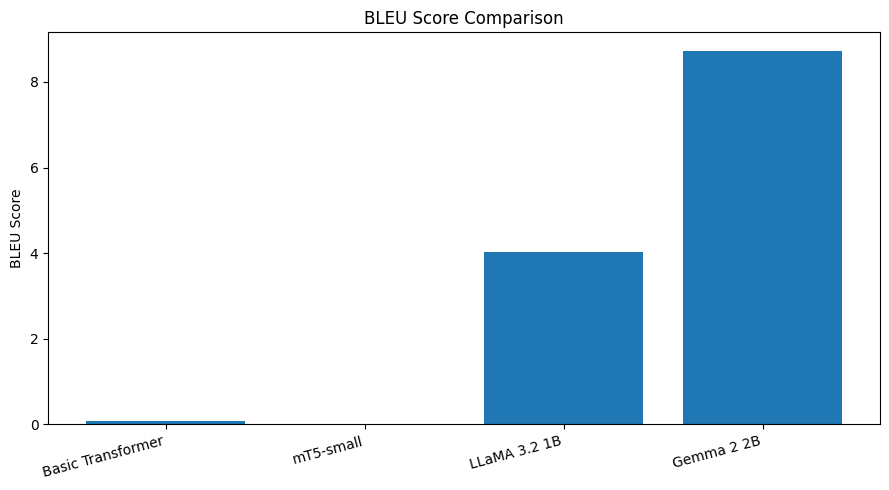

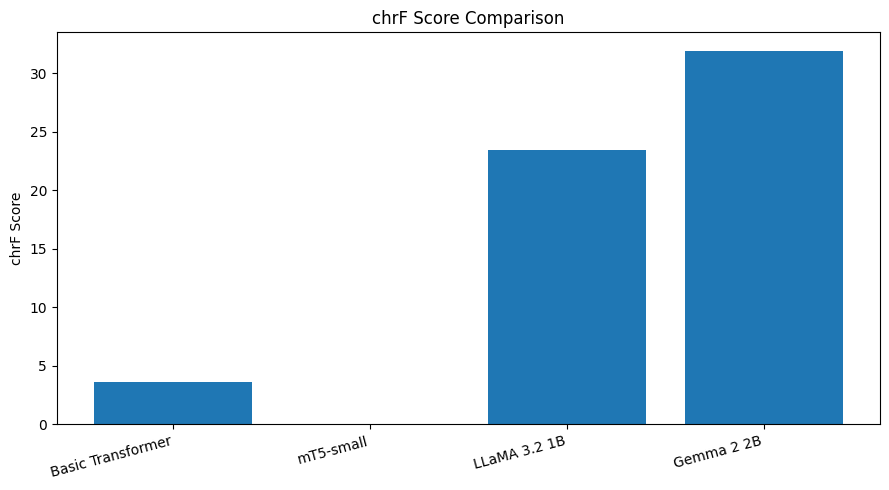

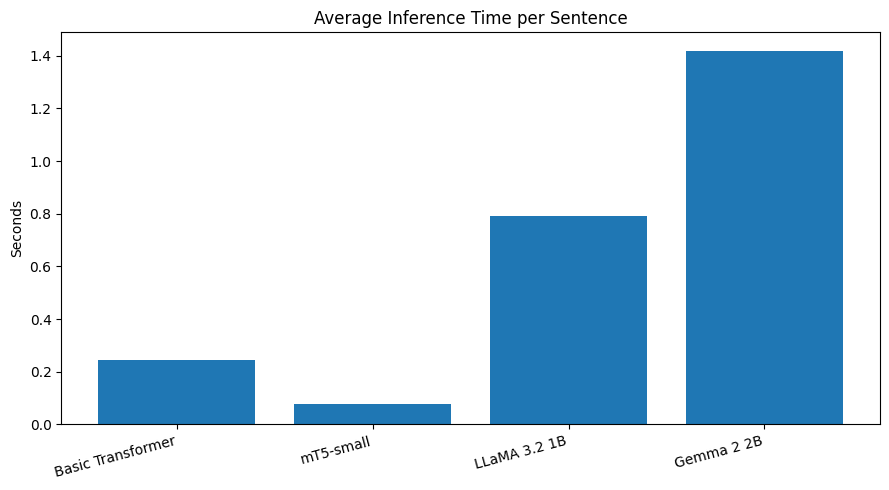

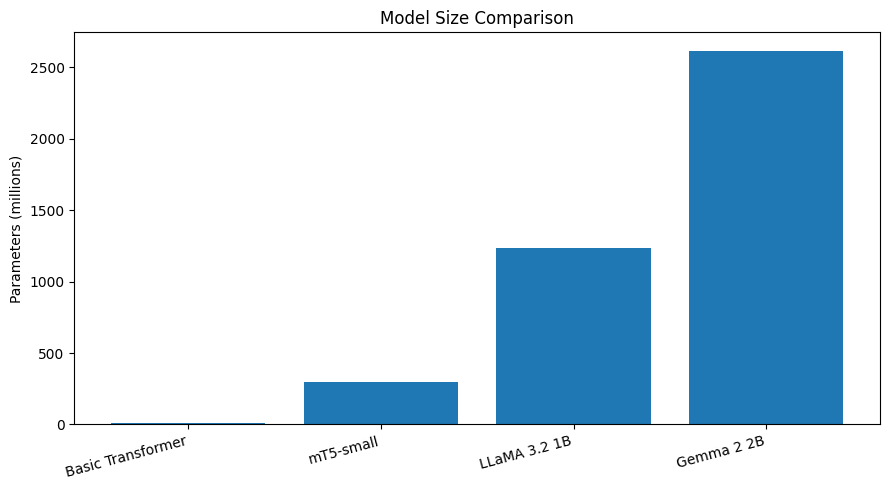

In [ ]:

import os, json, shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

WORK = "/kaggle/working/fgai_assignment3"
RESULTS = WORK + "/results"
os.makedirs(RESULTS, exist_ok=True)

# Load existing experimental results
comparison = pd.read_csv(RESULTS + "/model_comparison.csv")
if "Unnamed: 0" in comparison.columns:
    comparison = comparison.rename(columns={"Unnamed: 0": "Model"})

# Save clean comparison table
comparison.to_csv(RESULTS + "/final_model_comparison.csv", index=False)

print("FINAL MODEL COMPARISON")
display(comparison.round(4))

# 1. BLEU comparison
plt.figure(figsize=(9, 5))
plt.bar(comparison["Model"], comparison["BLEU"])
plt.title("BLEU Score Comparison")
plt.ylabel("BLEU Score")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.savefig(RESULTS + "/bleu_comparison.png", dpi=200)
plt.show()

# 2. chrF comparison
plt.figure(figsize=(9, 5))
plt.bar(comparison["Model"], comparison["chrF"])
plt.title("chrF Score Comparison")
plt.ylabel("chrF Score")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.savefig(RESULTS + "/chrf_comparison.png", dpi=200)
plt.show()

# 3. Inference time comparison
plt.figure(figsize=(9, 5))
plt.bar(comparison["Model"], comparison["avg_inference_seconds"])
plt.title("Average Inference Time per Sentence")
plt.ylabel("Seconds")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.savefig(RESULTS + "/inference_time_comparison.png", dpi=200)
plt.show()

# 4. Parameter count comparison
plt.figure(figsize=(9, 5))
plt.bar(comparison["Model"], comparison["parameters"] / 1e6)
plt.title("Model Size Comparison")
plt.ylabel("Parameters (millions)")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.savefig(RESULTS + "/parameter_comparison.png", dpi=200)
plt.show()

# Experiment metadata
metadata = {
    "task": "English-to-Hindi Neural Machine Translation",
    "dataset": "Hindi-English Parallel Corpus (Kaggle)",
    "dataset_source": "vaibhavkumar11/hindi-english-parallel-corpus",
    "sampled_pairs": 12000,
    "training_pairs_basic_transformer": 10000,
    "training_pairs_mt5": 1000,
    "validation_pairs_basic_transformer": 1000,
    "validation_pairs_mt5": 100,
    "test_pairs": 1000,
    "evaluation_examples": 200,
    "random_seed": 42,
    "hardware": "Kaggle NVIDIA Tesla T4 GPUs; experiments executed on cuda:0",
    "models": [
        "Basic Transformer encoder-decoder trained from scratch",
        "mT5-small fine-tuned",
        "LLaMA 3.2 1B Instruct zero-shot prompting",
        "Gemma 2 2B IT zero-shot prompting"
    ],
    "evaluation_metrics": ["BLEU", "chrF"],
    "limitations": [
        "The evaluation uses a 200-example subset of the held-out test set.",
        "Training data sizes differ between the Basic Transformer and mT5 experiments.",
        "LLaMA and Gemma use zero-shot prompting and were not fine-tuned.",
        "The Basic Transformer and mT5 results indicate ineffective translation learning.",
        "The dataset may contain noisy or misaligned translation pairs.",
        "Inference timings depend on hardware, generation settings and model size."
    ]
}

with open(RESULTS + "/final_experiment_metadata.json", "w") as f:
    json.dump(metadata, f, indent=4, ensure_ascii=False)

# Final concise findings
best_bleu = comparison.loc[comparison["BLEU"].idxmax(), "Model"]
best_chrf = comparison.loc[comparison["chrF"].idxmax(), "Model"]
fastest = comparison.loc[comparison["avg_inference_seconds"].idxmin(), "Model"]

findings = f"""
FINAL EXPERIMENT FINDINGS

Task: English-to-Hindi Neural Machine Translation

Best BLEU model: {best_bleu}
Best chrF model: {best_chrf}
Fastest average inference: {fastest}

Gemma 2 2B achieved the highest BLEU and chrF scores in this experiment.
LLaMA 3.2 1B was the second-best model on both translation metrics.
The Basic Transformer and mT5-small produced very low scores, indicating
that their current training configurations did not learn effective
translation behaviour.

The comparison is preliminary because model training data sizes and
adaptation approaches differ. LLaMA and Gemma were evaluated using
zero-shot prompting, while the Basic Transformer and mT5-small were
trained/fine-tuned.

All models were evaluated on the same 200 English test examples.
"""

with open(RESULTS + "/final_findings.txt", "w") as f:
    f.write(findings)

# Package entire project
zip_path = shutil.make_archive(
    "/kaggle/working/fgai_assignment3_final",
    "zip",
    WORK
)

print("\nFINALIZATION COMPLETE")
print("Results folder:", RESULTS)
print("ZIP file:", zip_path)
print("\nGenerated files:")
for f in sorted(os.listdir(RESULTS)):
    print("-", f)

print("\n", findings)
